### [Pillar 1: Ingestion & Capture] — Cell 1: Download & Cache Raw Exoplanet Data

In [9]:
import os
import pandas as pd

RAW_FILE = "exoplanets_raw.csv"
TAP_URL = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query=select+pl_name,hostname,discoverymethod,disc_year,sy_snum,sy_pnum,pl_orbper,pl_rade,pl_bmasse,pl_eqt,st_teff,sy_dist+from+pscomppars&format=csv"

if os.path.exists(RAW_FILE):
    df_raw = pd.read_csv(RAW_FILE)
    print("File loaded from disk")
else:
    df_raw = pd.read_csv(TAP_URL)
    df_raw.to_csv(RAW_FILE, index=False)
    print("File downloaded from web and saved to disk")

print(f"Dataset dimensions(Rows, Columns): {df_raw.shape}")
df_raw.head()

File loaded from disk
Dataset dimensions(Rows, Columns): (6470, 12)


,pl_name,hostname,discoverymethod,disc_year,sy_snum,sy_pnum,pl_orbper,pl_rade,pl_bmasse,pl_eqt,st_teff,sy_dist
0,Kepler-257 d,Kepler-257,Transit,2014,1,3,24.664551,4.950000,21.70,567.00,5180.0,780.2560
1,TOI-1758 b,TOI-1758,Transit,2024,1,1,20.705075,3.620000,6.90,551.44,5169.0,96.6215
2,Kepler-607 c,Kepler-607,Transit,2021,1,2,39.676800,2.760012,8.05,473.00,5244.0,519.1220
3,Kepler-1040 b,Kepler-1040,Transit,2016,1,1,201.121400,2.080000,4.98,300.00,5694.0,482.1190
4,Kepler-343 b,Kepler-343,Transit,2014,1,2,8.968550,2.410000,6.39,1024.00,5807.0,927.1930


### Column Dictionary (`pscomppars` Table)
* **`pl_name` / `hostname`**: Planet name / Host star name.
* **`discoverymethod`**: Technique used to find the planet.
* **`disc_year`**: Year the discovery was published.
* **`sy_snum` / `sy_pnum`**: Number of stars in the system / Number of planets in the system.
* **`pl_orbper`**: Orbital period in **Earth days** (1 year on that planet).
* **`pl_rade`**: Planet radius in **Earth radii** (`1.0` = Earth size, `11.2` = Jupiter size).
* **`pl_bmasse`**: Planet mass in **Earth masses** (`1.0` = Earth weight, `317.8` = Jupiter weight).
* **`pl_eqt`**: Planet equilibrium temperature in **Kelvin** (`255 K` = Earth, `0 K` = absolute zero).
* **`st_teff`**: Host star surface temperature in **Kelvin** (`5778 K` = our Sun).
* **`sy_dist`**: Distance from Earth in **parsecs** (`1 pc` ≈ 3.26 light-years).

### [Pillar 2: Preparation & Cleaning] — Cell 2: Audit Data Types & Count Missing Values

In [14]:
df_raw.info()

missing_count = df_raw.isna().sum()
missing_pct = (df_raw.isna().mean() * 100).round(2)
missing_summary = pd.DataFrame({"Missing Count": missing_count, "Missing %": missing_pct})

missing_summary

<class 'pandas.DataFrame'>
RangeIndex: 6470 entries, 0 to 6469
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pl_name          6470 non-null   str    
 1   hostname         6470 non-null   str    
 2   discoverymethod  6470 non-null   str    
 3   disc_year        6470 non-null   int64  
 4   sy_snum          6470 non-null   int64  
 5   sy_pnum          6470 non-null   int64  
 6   pl_orbper        6114 non-null   float64
 7   pl_rade          6420 non-null   float64
 8   pl_bmasse        6439 non-null   float64
 9   pl_eqt           5930 non-null   float64
 10  st_teff          6161 non-null   float64
 11  sy_dist          6442 non-null   float64
dtypes: float64(6), int64(3), str(3)
memory usage: 606.7 KB


,Missing Count,Missing %
pl_name,0,0.00
hostname,0,0.00
discoverymethod,0,0.00
disc_year,0,0.00
sy_snum,0,0.00
sy_pnum,0,0.00
pl_orbper,356,5.50
pl_rade,50,0.77
pl_bmasse,31,0.48
pl_eqt,540,8.35


### [Pillar 2: Preparation & Cleaning] — Cell 3: Audit Number Ranges, Skew & Category Counts

In [19]:
print(df_raw["discoverymethod"].value_counts())
df_raw.describe().round(2)

discoverymethod
Transit                          4799
Radial Velocity                  1205
Microlensing                      294
Imaging                            98
Transit Timing Variations          29
Eclipse Timing Variations          17
Orbital Brightness Modulation       9
Astrometry                          8
Pulsar Timing                       8
Pulsation Timing Variations         2
Disk Kinematics                     1
Name: count, dtype: int64


,disc_year,sy_snum,sy_pnum,pl_orbper,pl_rade,pl_bmasse,pl_eqt,st_teff,sy_dist
count,6470.00,6470.00,6470.00,6.114000e+03,6420.00,6439.00,5930.00,6161.00,6442.00
mean,2017.43,1.10,1.75,7.002122e+04,5.85,404.41,836.95,5390.26,705.40
std,5.22,0.34,1.14,5.143593e+06,5.40,1149.19,496.35,1717.55,1233.29
min,1992.00,1.00,1.00,9.000000e-02,0.31,0.02,1.48,415.00,1.30
25%,2014.00,1.00,1.00,4.290000e+00,1.85,4.35,486.09,4894.00,99.56
50%,2016.00,1.00,1.00,1.064000e+01,2.86,9.32,757.77,5544.00,348.60
75%,2021.00,1.00,2.00,3.805000e+01,11.90,190.00,1095.00,5900.00,816.56
max,2026.00,4.00,8.00,4.020000e+08,87.21,12651.50,7777.78,57000.00,8500.00


### Reference Guide for Cell 3: Discovery Methods & Summary Statistics

**Major Exoplanet Discovery Methods:**
* **Transit (4,799 planets — 74.2%):** Measures the tiny dip in a star's brightness when a planet passes directly in front of the star from Earth's point of view. Directly measures **planet radius (`pl_rade`)**.
* **Radial Velocity / "Wobble Method" (1,205 planets — 18.6%):** Measures the slight back-and-forth gravitational wobble of a star (via Doppler shifts in its starlight) as an orbiting planet tugs on it. Directly measures **planet mass (`pl_bmasse`)**.
* **Microlensing (294 planets — 4.5%):** Uses gravity as a magnifying glass when a foreground star passes in front of a distant background star, briefly bending and brightening its light.
* **Imaging (98 planets — 1.5%):** Taking a direct telescope photograph of huge, hot, young gas giants orbiting very far away from their host star.
* **Timing Variations & Astrometry (65 planets combined — ~1.2%):** Detecting planets by slight gravitational delays in transit/eclipse/pulsar clocks or tiny shifts in a star's sky position.

**What the Rows in `.describe()` Mean:**
* **`count`**: Number of non-empty rows in that column.
* **`mean`**: The standard average (sum of all values divided by `count`). Sensitive to extreme outliers!
* **`std` (Standard Deviation)**: Measures how spread out the numbers are around the `mean`. A small `std` means values cluster tightly together; a huge `std` means the data spans wild extremes.
* **`min`**: The smallest value in the column.
* **`25%` / `50%` (Median) / `75%`**: The quartiles. If you line up all planets from smallest to largest, `50%` is the exact middle planet. Unlike `mean`, the `50%` median is **not** skewed by extreme outliers.
* **`max`**: The largest value in the column.
* *(Note on `e+04` scientific notation: `1.064e+01` means $1.064 \times 10^1 = 10.64$, and `4.02e+08` means $4.02 \times 10^8 = 402,000,000$).*

### [Pillar 2: Preparation & Cleaning] — Cell 4: Filter Incomplete Rows & Save Clean Dataset

In [21]:
df_clean = df_raw.dropna(subset=["pl_orbper", "pl_rade", "pl_bmasse", "st_teff"]).copy()

print(f"Rows in raw database: {len(df_raw)}")
print(f"Rows in cleaned database: {len(df_clean)}")
print(f"Rows dropped in cleaning: {len(df_raw) - len(df_clean)}")

df_clean.to_csv("exoplanets_clean.csv", index=False)

Rows in raw database: 6470
Rows in cleaned database: 6019
Rows dropped in cleaning: 451


### [Pillar 3: Exploration & Analysis] — Cell 5: Group by Discovery Method to Expose Telescope Biases

In [29]:
method_summary = (
    df_clean.groupby("discoverymethod")
    .agg(
        planet_count=("pl_name", "count"),
        median_period_days=("pl_orbper", "median"),
        median_radius_earth=("pl_rade", "median"),
        median_mass_earth=("pl_bmasse", "median"),
        median_dist_pc=("sy_dist", "median")
    )
    .round(2)
    .sort_values(by="planet_count", ascending=False)
)

method_summary

,planet_count,median_period_days,median_radius_earth,median_mass_earth,median_dist_pc
discoverymethod,,,,,
Transit,4772,8.01,2.45,6.98,455.48
Radial Velocity,1166,319.70,12.60,314.65,45.88
Transit Timing Variations,28,43.33,9.70,67.99,334.10
Imaging,22,33100.00,13.00,3089.15,41.24
Eclipse Timing Variations,14,3192.50,12.90,1508.42,396.33
Astrometry,7,558.67,12.10,6293.00,49.84
Orbital Brightness Modulation,6,1.62,13.40,397.29,772.03
Microlensing,2,4824.34,13.25,962.95,2120.00
Pulsation Timing Variations,2,1005.00,12.75,2383.72,1289.44


### Reference Guide for Cell 5: Column Definitions & Discovery Methods

**Summary Column Definitions:**
* **`median_period_days`**: The middle orbital period in **Earth days** (how long 1 full orbit / "1 year" takes for a typical planet found by this method).
* **`median_radius_earth`**: The middle planet physical radius in **Earth radii** (`1.0` = Earth size, `3.9` = Neptune size, `11.2` = Jupiter size).
* **`median_mass_earth`**: The middle planet mass in **Earth masses** (`1.0` = Earth weight, `17.1` = Neptune weight, `317.8` = Jupiter weight).
* **`median_dist_pc`**: The middle distance from Earth to the star system in **parsecs** (`1 pc` ≈ 3.26 light-years).

**Discovery Methods in `df_clean`:**
* **Transit (`4,772` planets):** Detects the slight dip in starlight when a planet crosses in front of its star. Strongly favors close-in planets (`8.01` days) and smaller sub-Neptune worlds (`2.45` Earth radii, `6.98` Earth masses) deep in space (`455.48` pc).
* **Radial Velocity (`1,166` planets):** Detects the gravitational back-and-forth "wobble" of a star via Doppler shifts. Strongly favors heavy Jupiter-twins (`314.65` Earth masses, `12.60` Earth radii) on wider orbits (`319.70` days) around nearby bright stars (`45.88` pc).
* **Transit Timing Variations (`28` planets):** Detects gravitational tugs between multiple planets in the same system when a transiting planet arrives slightly early or late.
* **Imaging (`22` planets):** Direct telescope photographs of young, super-massive gas giants (`3,089.15` Earth masses) orbiting very far from their star's glare (`33,100` days / ~90.6 Earth years) around nearby stars (`41.24` pc).
* **Eclipse / Pulsation Timing Variations (`16` planets combined):** Detects planets by measuring tiny light-travel-time delays in eclipsing binary stars or pulsating stars.
* **Astrometry (`7` planets):** Measures the tiny side-to-side shift of a star's position on the sky caused by a very massive orbiting companion (`6,293` Earth masses).
* **Orbital Brightness Modulation (`6` planets):** Detects ultra-close planets (`1.62` days) by measuring phases of reflected light or gravitational stretching of the star.
* **Microlensing (`2` planets with complete parameters):** Uses gravity from a foreground star system to magnify light from a distant background star (`2,120` pc away).

## [Pillar 3: Exploration & Analysis]

In [32]:
df_clean["density_gcc"] = (df_clean["pl_bmasse"] / (df_clean["pl_rade"] ** 3)) * 5.51

df_clean["size_class"] = pd.cut(df_clean["pl_rade"], bins=[0, 1.25, 2.0, 4.0, 100], labels=["1. Earth-sized (<1.25 R_E)", "2. Super-Earth (1.25-2.0 R_E)", "3. Sub-Neptune (2.0-4.0 R_E)", "4. Gas Giant (>4.0 R_E)"])

size_summary = df_clean.groupby("size_class", observed=True).agg(planet_count=("pl_name", "count"), median_radius=("pl_rade", "median"), median_mass=("pl_bmasse", "median"), median_density_gcc=("density_gcc", "median"), median_orbper_days=("pl_orbper", "median")).round(2)

size_summary

,planet_count,median_radius,median_mass,median_density_gcc,median_orbper_days
size_class,,,,,
1. Earth-sized (<1.25 R_E),597,1.06,1.32,5.67,4.52
2. Super-Earth (1.25-2.0 R_E),1203,1.60,3.33,4.43,6.67
3. Sub-Neptune (2.0-4.0 R_E),2075,2.63,7.65,2.31,14.01
4. Gas Giant (>4.0 R_E),2144,12.60,292.40,0.97,23.45


### Reference Guide for Cell 6: Size Classes & Bulk Density Takeaways
* **`density_gcc` (Bulk Density in $\text{g/cm}^3$):** Measures how tightly packed a planet's mass is relative to its volume ($\text{Mass} / \text{Radius}^3 \times 5.51$). Liquid water is `1.00 g/cm³`; Earth is `5.51 g/cm³`.
* **Earth-sized (`5.67 g/cm³`) & Super-Earths (`4.43 g/cm³`):** High densities confirm these worlds are made of solid rock and iron cores.
* **The `2.0 R_E` Transition to Sub-Neptunes (`2.31 g/cm³`):** Above `2.0` Earth radii, median density drops by nearly 50%. Planets above this threshold retain thick envelopes of volatile gases (hydrogen/helium) or deep water-ice layers that puff up their radius without adding proportional mass.
* **Gas Giants (`0.97 g/cm³`):** With a median radius of `12.60` Earths and median mass of `292.40` Earths, typical gas giants are slightly less dense than liquid water (`1.00 g/cm³`).

## [Pillar 4: Communication & Action] — Cell 7: Visualize Planet Radius & Mass-Radius Distributions

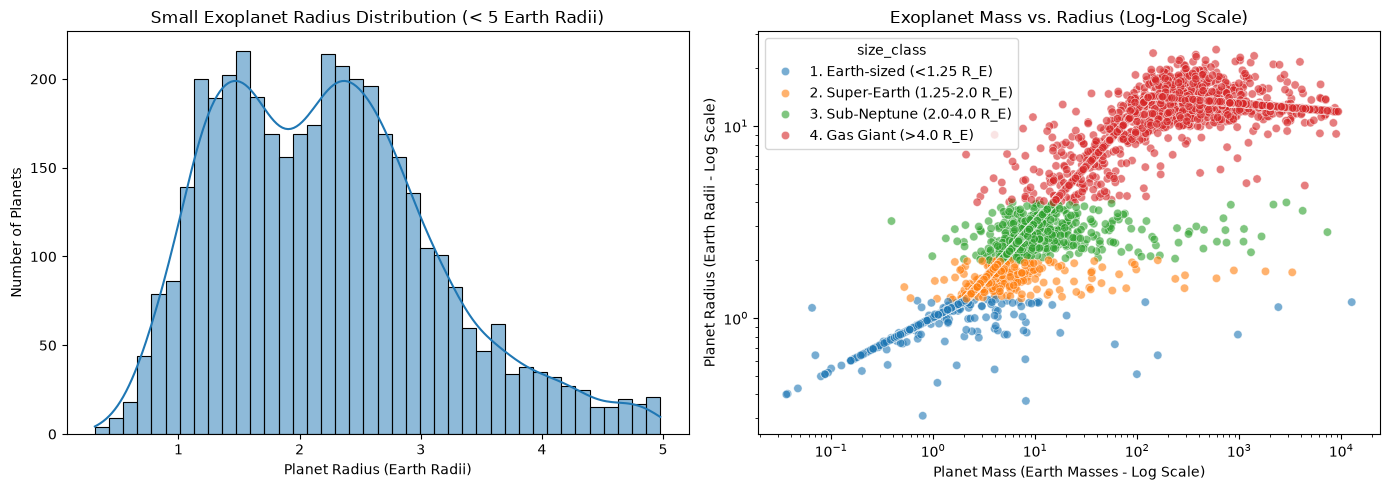

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

small_planets = df_clean[df_clean["pl_rade"] < 5.0]

sns.histplot(data=small_planets, x="pl_rade", bins=40, kde=True, ax=ax1)
ax1.set_title("Small Exoplanet Radius Distribution (< 5 Earth Radii)")
ax1.set_xlabel("Planet Radius (Earth Radii)")
ax1.set_ylabel("Number of Planets")

sns.scatterplot(data=df_clean, x="pl_bmasse", y="pl_rade", hue="size_class", alpha=0.6, ax=ax2)
ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_title("Exoplanet Mass vs. Radius (Log-Log Scale)")
ax2.set_xlabel("Planet Mass (Earth Masses - Log Scale)")
ax2.set_ylabel("Planet Radius (Earth Radii - Log Scale)")

plt.tight_layout()
plt.savefig("exoplanet_distributions.png", dpi=300)
plt.show()

### Reference Guide for Cell 7: Visual Takeaways & Physical Laws

* **Left Chart — The "Fulton Radius Valley" (`~1.8 - 2.0 R_E` Dip):**
  - Instead of a single smooth bell curve, small exoplanets split into two distinct peaks: **bare rocky Super-Earths (`~1.4 R_E`)** and **gaseous Sub-Neptunes (`~2.4 R_E`)**, separated by a valley around `1.8 - 2.0 R_E`.
  - **Physical Cause (Photoevaporation):** Close-in planets are blasted by extreme stellar radiation. Smaller cores lose their gas envelopes completely and shrink to the `1.4 R_E` rocky peak, while heavier cores retain thick hydrogen/helium atmospheres and stay inflated at `2.4 R_E`.
* **Right Chart — Mass-Radius Power Law & Gas Giant Compression:**
  - **Rocky to Sub-Neptune Climb (`10^-1` to `10^2 M_E`):** As mass increases from Earth-sized worlds (`blue`) through Super-Earths (`orange`) and Sub-Neptunes (`green`), radius climbs steadily.
  - **Gas Giant Plateau (`10^2` to `10^4 M_E`):** Above `~100` Earth masses (`red`), the curve flattens horizontally around `~11–13 R_E` (`~1` Jupiter radius). Due to gravitational self-compression and electron degeneracy pressure, adding more mass (all the way into the Brown Dwarf regime at `>4,000 M_E`) packs matter more tightly into the core rather than increasing the planet's physical diameter.